In [1]:
%matplotlib inline
import pandas as pd
import plotting_utils as pu

### Figure 2 a

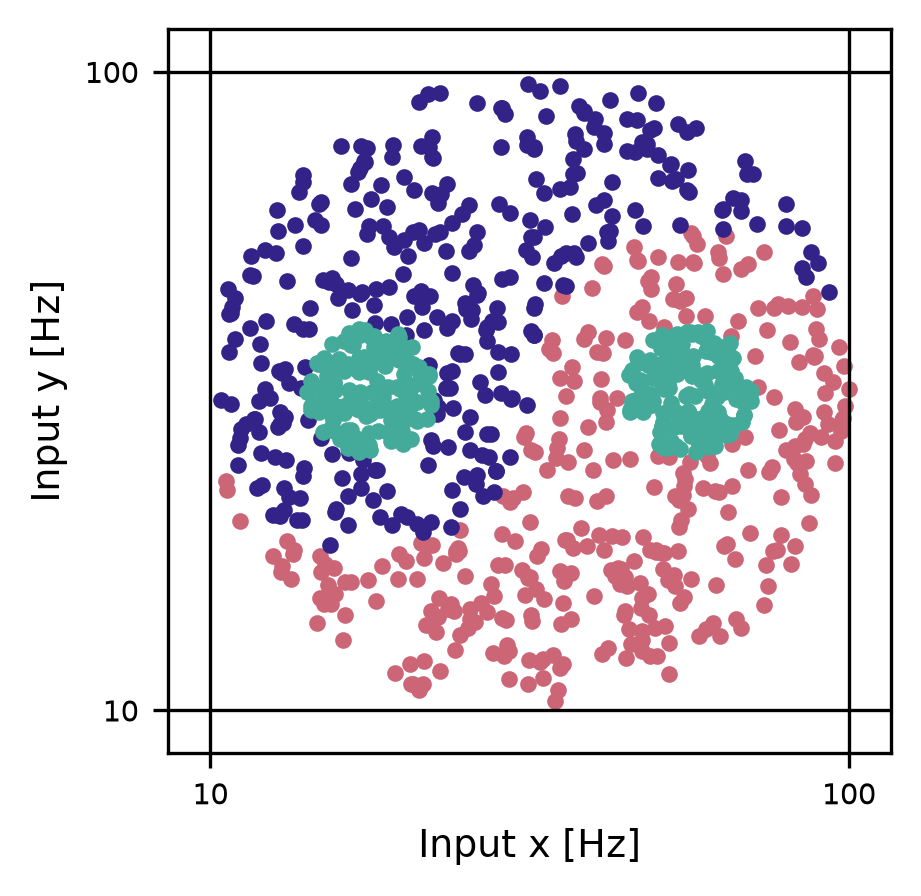

In [2]:
dyn_predictions_df = pd.read_csv('../data/dynapse/yinyang_predictions.csv')
fig = pu.plot_predictions(dyn_predictions_df, class_col='true_label')
fig.savefig('../figures/fig2a.pdf', bbox_inches='tight')
fig.savefig('../figures/fig2a.png', bbox_inches='tight')

### Figure 2 b

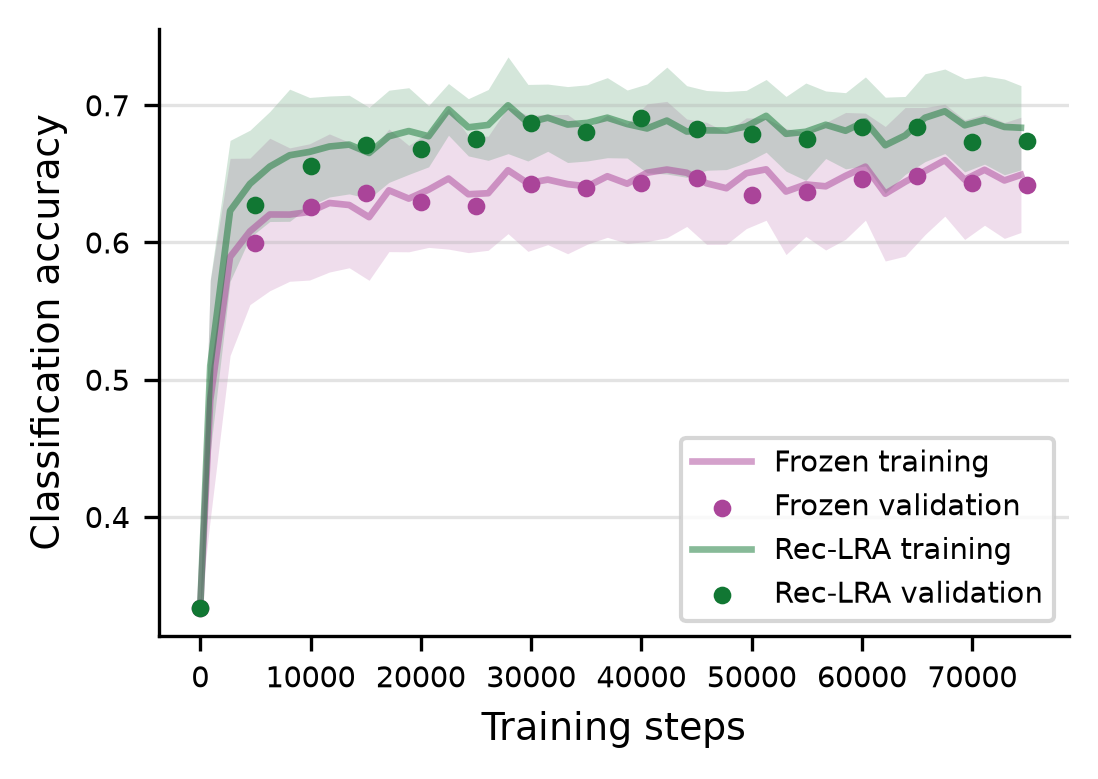

In [3]:
dyn_yinyang_df = pd.read_csv('../data/dynapse/yinyang_accuracy.csv')
dyn_yinyang_agg = pu.aggregate_mean_std(dyn_yinyang_df)
ax = pu.plot_accuracy_over_steps(dyn_yinyang_agg, chance_level=1 / 3)  # 3 classes
ax.figure.savefig('../figures/fig2b.pdf', bbox_inches='tight')
ax.figure.savefig('../figures/fig2b.png', bbox_inches='tight')

### Figure 2c

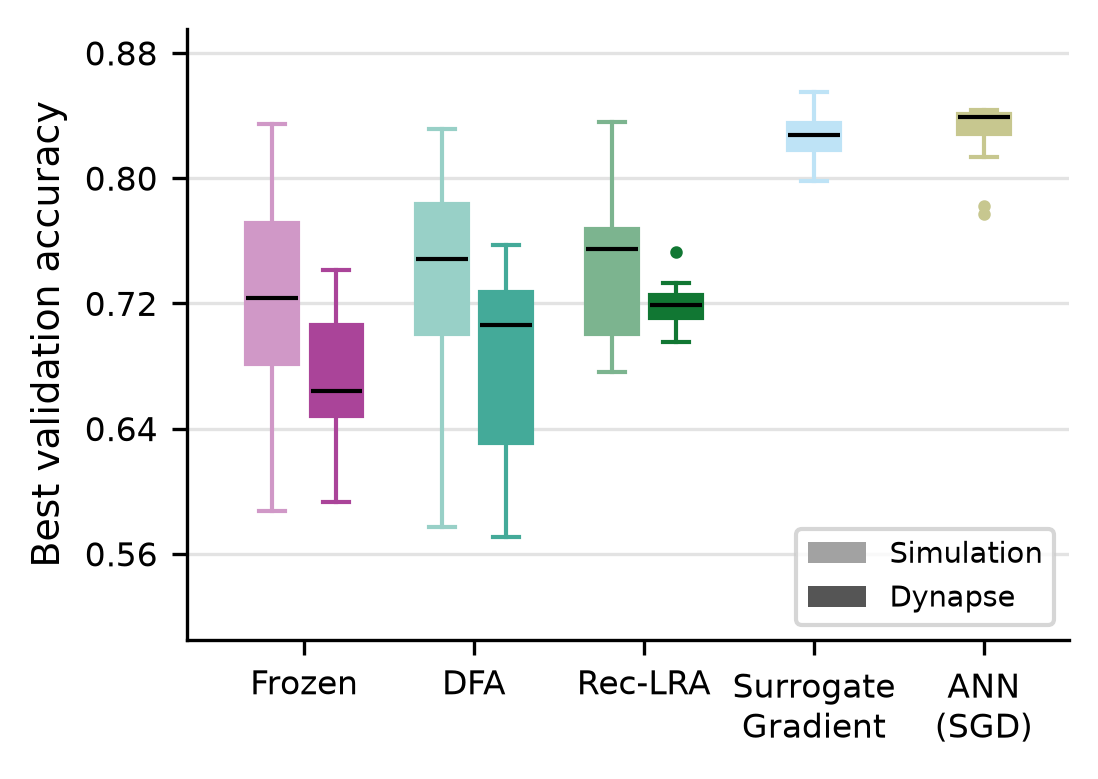

In [4]:
sim_yinyang_files = [
    '../data/simulation/yinyang_accuracy_sfc.csv',
    '../data/simulation/yinyang_accuracy_surrogategrad_MSE.csv',
    '../data/simulation/yinyang_accuracy_backprop_crossentropy.csv'
]
sim_yinyang_dfs = [pd.read_csv(f, sep=';') for f in sim_yinyang_files]
sim_yinyang_df = pd.concat(sim_yinyang_dfs, ignore_index=True)

# TODO: update sims with test accuracy 
if 'test accuracy (Max)' not in sim_yinyang_df.columns:
    sim_yinyang_df['test accuracy (Max)'] = None
sim_yinyang_df['test accuracy (Max)'] = sim_yinyang_df['test accuracy (Max)'].fillna(
    sim_yinyang_df.get('eval accuracy')
).fillna(
    sim_yinyang_df.get('test accuracy (max)')
)

fig = pu.plot_sim_vs_dynapse_box_plots(dyn_yinyang_df, sim_yinyang_df, y_min=0.505, y_max=0.895,
                                       legend_loc='lower right')
fig.savefig('../figures/fig2c.pdf', bbox_inches='tight')
fig.savefig('../figures/fig2c.png', bbox_inches='tight')

### Figure 2 d

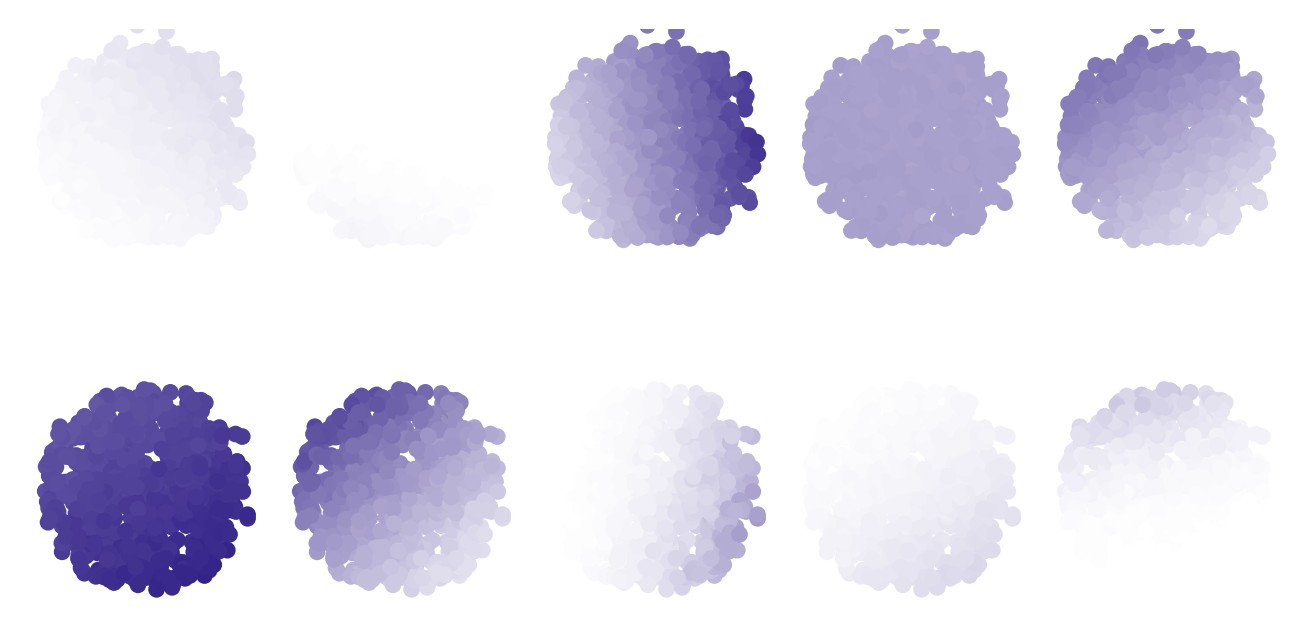

In [5]:
dyn_hidden_df = pd.read_csv('../data/dynapse/yinyang_hidden_activity.csv')
chip2_df = dyn_hidden_df[dyn_hidden_df['chip'] == 2]
selected_neurons = pu.select_most_changed_neurons(chip2_df, init_step=0, final_step=75000, max_neurons=5)
fig = pu.plot_hidden_feature_maps(chip2_df[chip2_df['step'].isin([0, 75000])], neuron_indices=selected_neurons)
fig.savefig('../figures/fig2d.pdf', bbox_inches='tight')
fig.savefig('../figures/fig2d.png', bbox_inches='tight')

### Figure 2 e

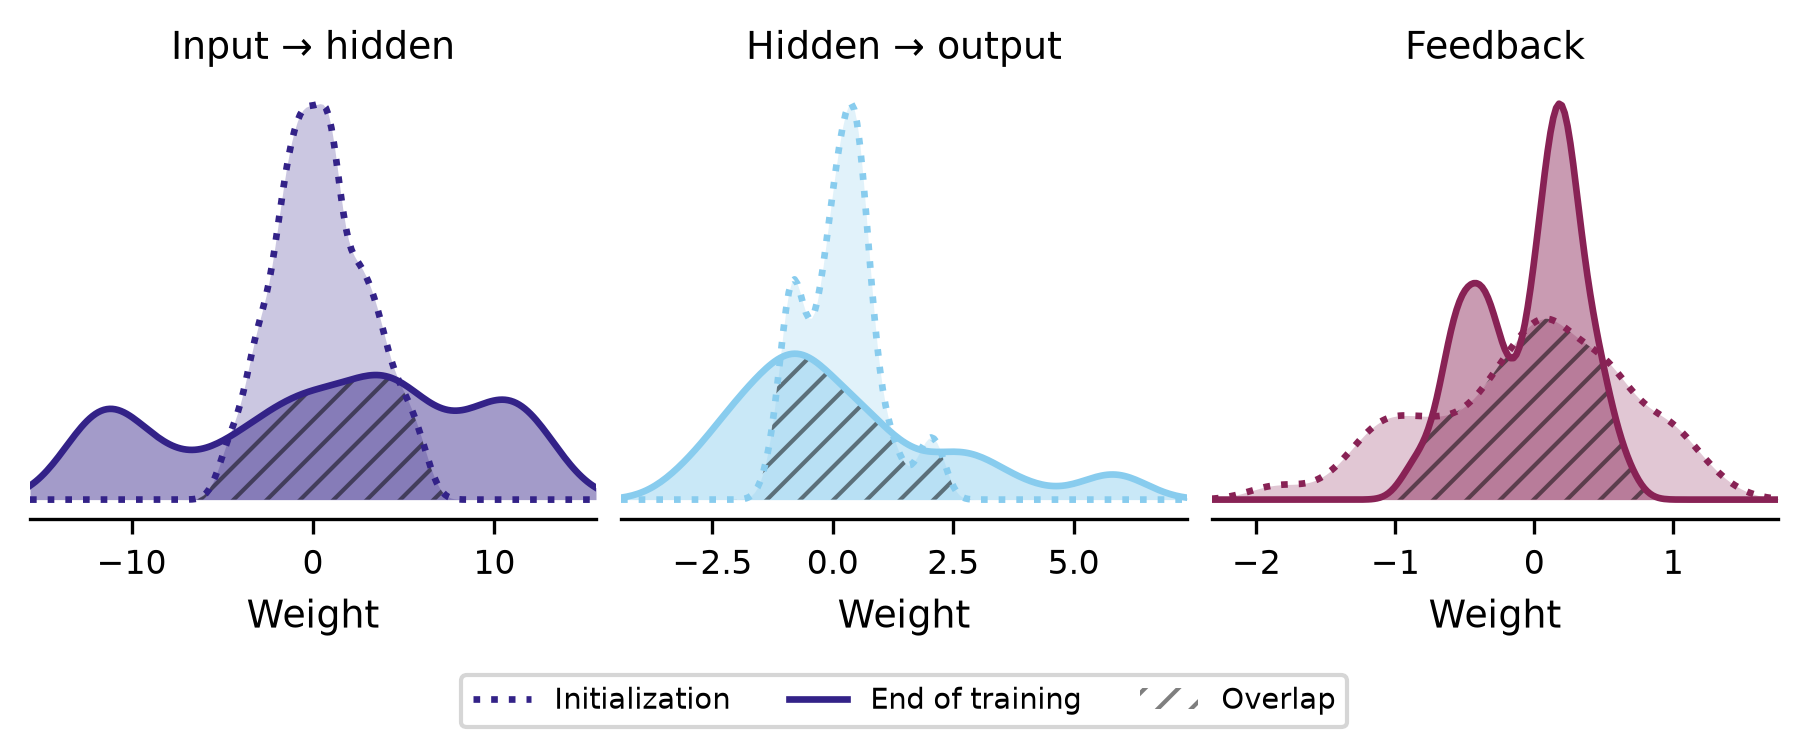

In [6]:
dyn_weights_df = pd.read_csv('../data/dynapse/yinyang_weight_distributions.csv')
fig = pu.plot_weight_distributions(dyn_weights_df, pu.YINYANG_WEIGHT_COLOR, pu.YINYANG_WEIGHT_TITLE)
fig.savefig('../figures/fig2e.pdf', bbox_inches='tight')
fig.savefig('../figures/fig2e.png', bbox_inches='tight')

### Figure 2 f

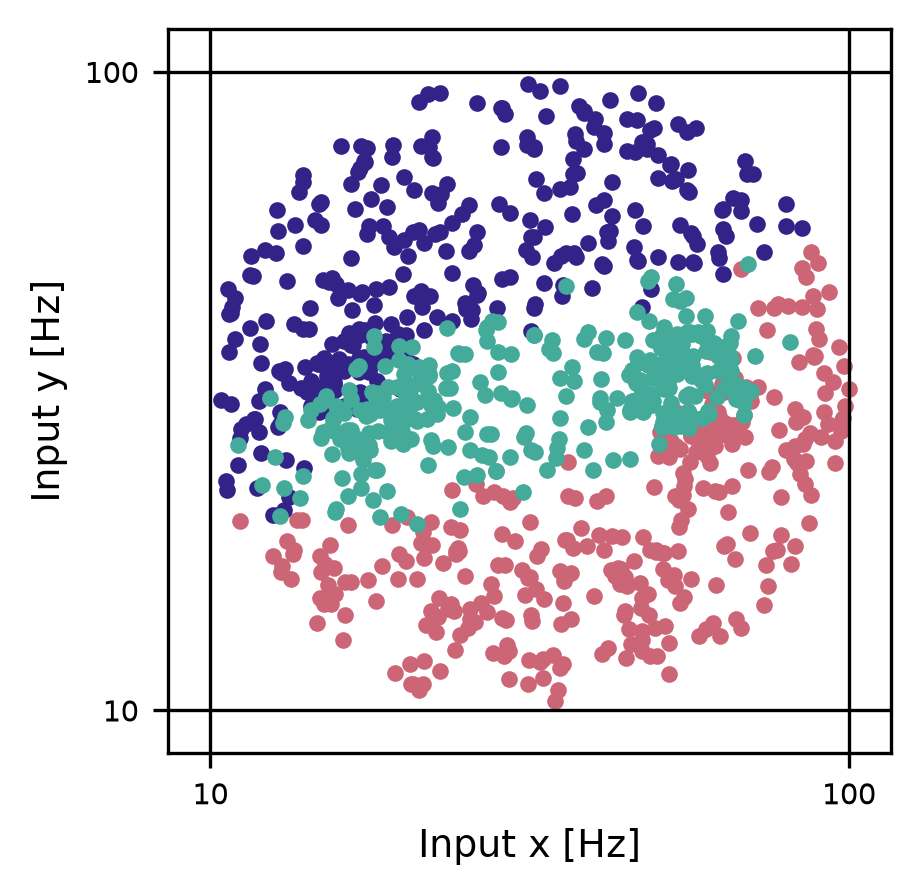

In [7]:
dyn_predictions_df = pd.read_csv('../data/dynapse/yinyang_predictions.csv')
fig = pu.plot_predictions(dyn_predictions_df)
fig.savefig('../figures/fig2f.pdf', bbox_inches='tight')
fig.savefig('../figures/fig2f.png', bbox_inches='tight')

### Figure 3 b

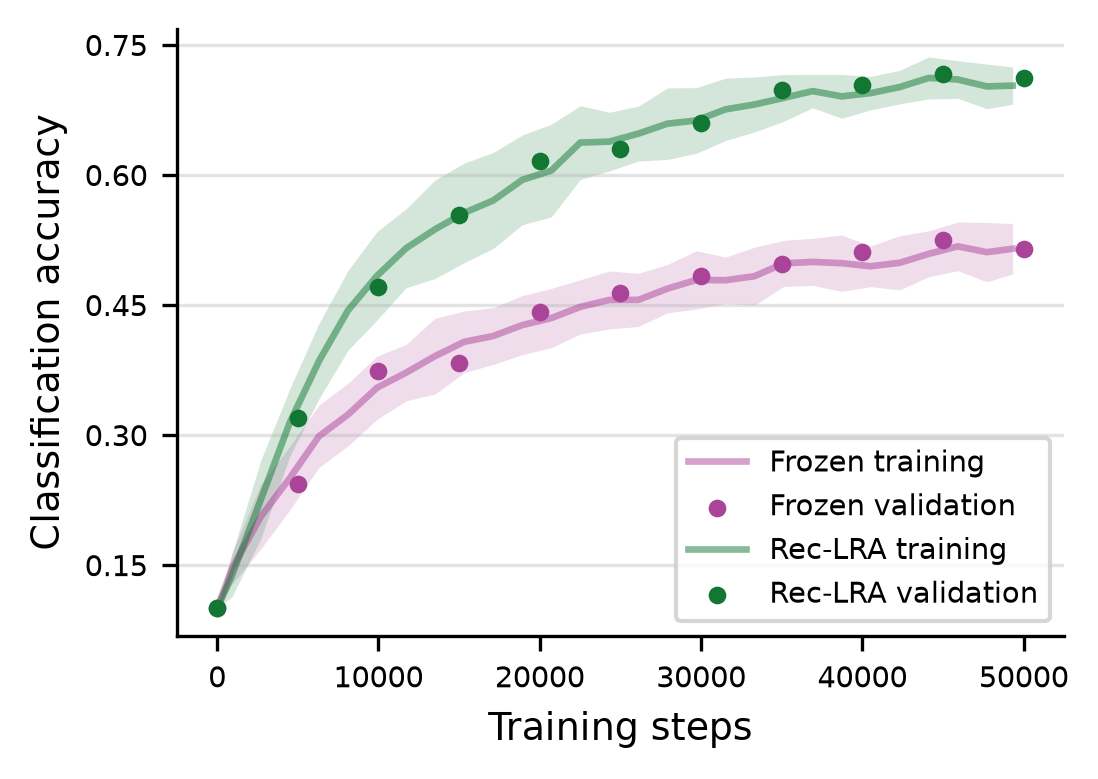

In [8]:
dyn_mnist1d_df = pd.read_csv('../data/dynapse/mnist1d_accuracy.csv')
dyn_mnist1d_agg = pu.aggregate_mean_std(dyn_mnist1d_df)
ax = pu.plot_accuracy_over_steps(dyn_mnist1d_agg, chance_level=0.1)  # 10 classes
ax.figure.savefig('../figures/fig3b.pdf', bbox_inches='tight')
ax.figure.savefig('../figures/fig3b.png', bbox_inches='tight')

### Figure 3c

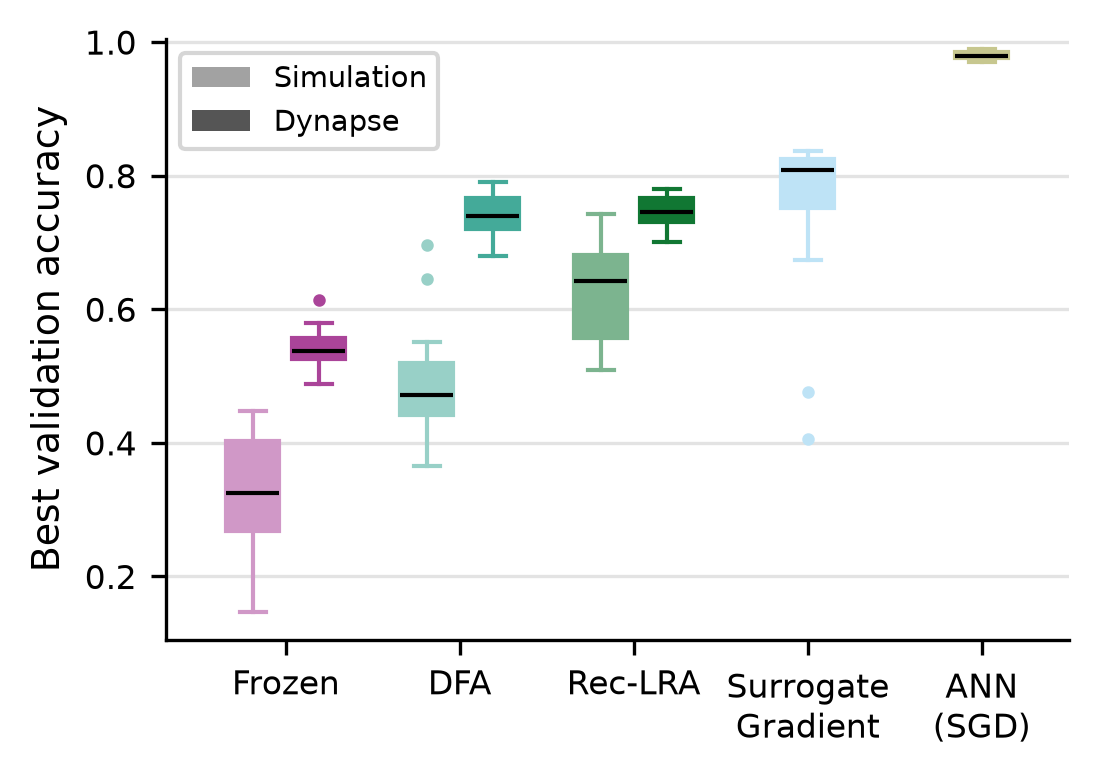

In [9]:
sim_mnist1d_files = [
    '../data/simulation/mnist1d_accuracy_sfc.csv',
    '../data/simulation/mnist1d_accuracy_surrogategrad_crossentropy.csv',
    '../data/simulation/mnist1d_accuracy_backprop_crossentropy.csv'
]
sim_mnist1d_dfs = [pd.read_csv(f, sep=';') for f in sim_mnist1d_files]
sim_mnist1d_df = pd.concat(sim_mnist1d_dfs, ignore_index=True)

# TODO: update sims with test accuracy 
if 'test accuracy (Max)' not in sim_mnist1d_df.columns:
    sim_mnist1d_df['test accuracy (Max)'] = None
sim_mnist1d_df['test accuracy (Max)'] = sim_mnist1d_df['test accuracy (Max)'].fillna(
    sim_mnist1d_df.get('eval accuracy')
).fillna(
    sim_mnist1d_df.get('test accuracy (max)')
)

# Frozen -> DFA -> Rec-LRA (simulation + Dynapse), then the simulation-only baselines.
fig = pu.plot_sim_vs_dynapse_box_plots(dyn_mnist1d_df, sim_mnist1d_df, y_min=0.105, y_max=1.005)
fig.savefig('../figures/fig3c.pdf', bbox_inches='tight')
fig.savefig('../figures/fig3c.png', bbox_inches='tight')

### Figure 3 d

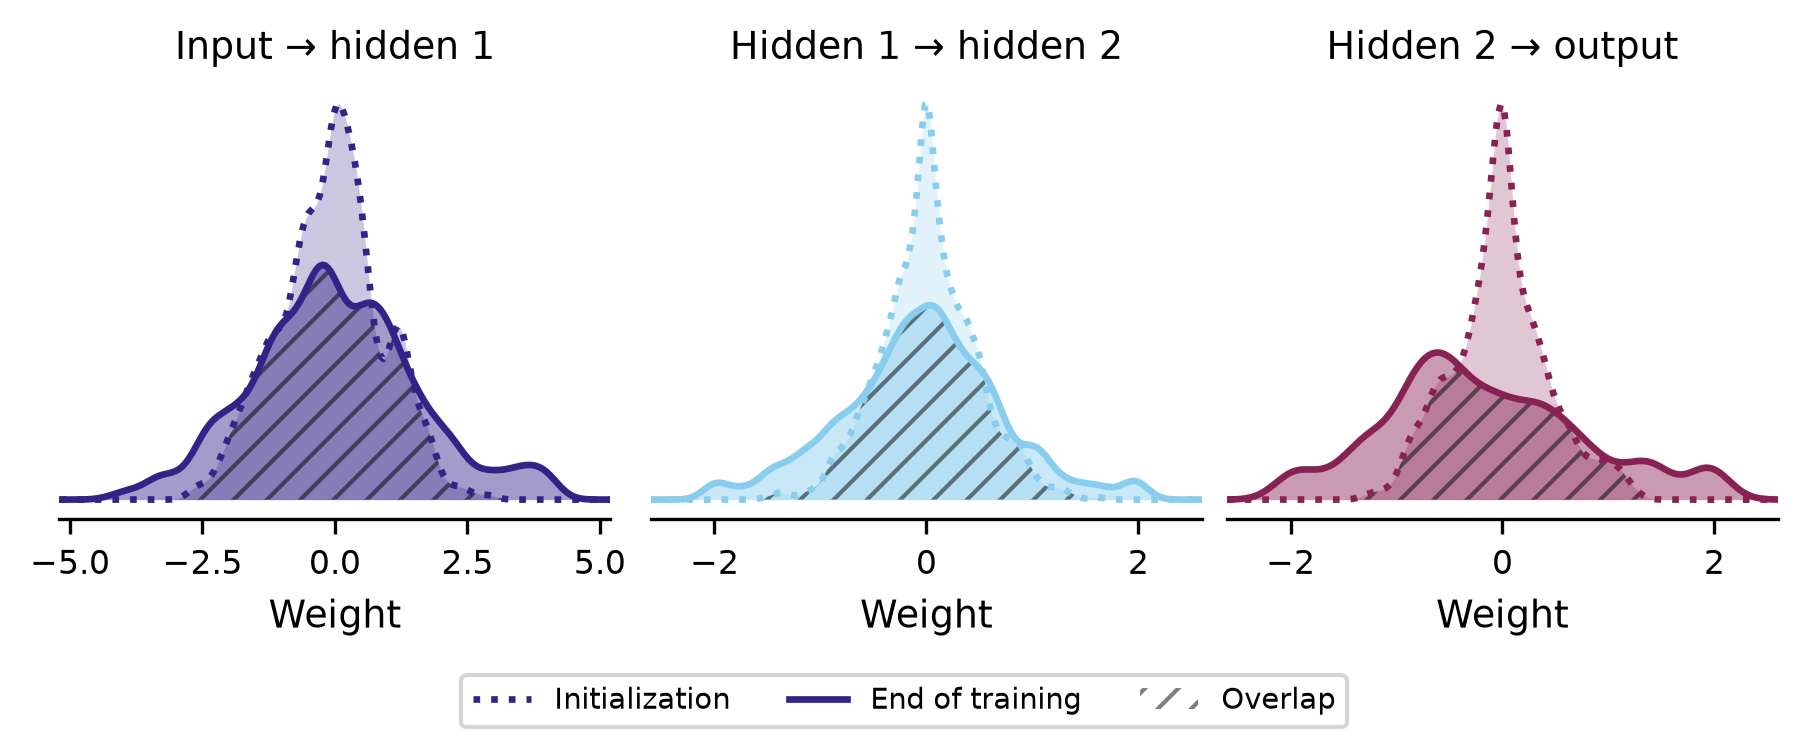

In [10]:
dyn_mnist1d_weights_df = pd.read_csv('../data/dynapse/mnist1d_weight_distributions.csv')
fig = pu.plot_weight_distributions(dyn_mnist1d_weights_df, pu.MNIST1D_WEIGHT_COLOR, pu.MNIST1D_WEIGHT_TITLE)
fig.savefig('../figures/fig3d.pdf', bbox_inches='tight')
fig.savefig('../figures/fig3d.png', bbox_inches='tight')

### Figure 3 f

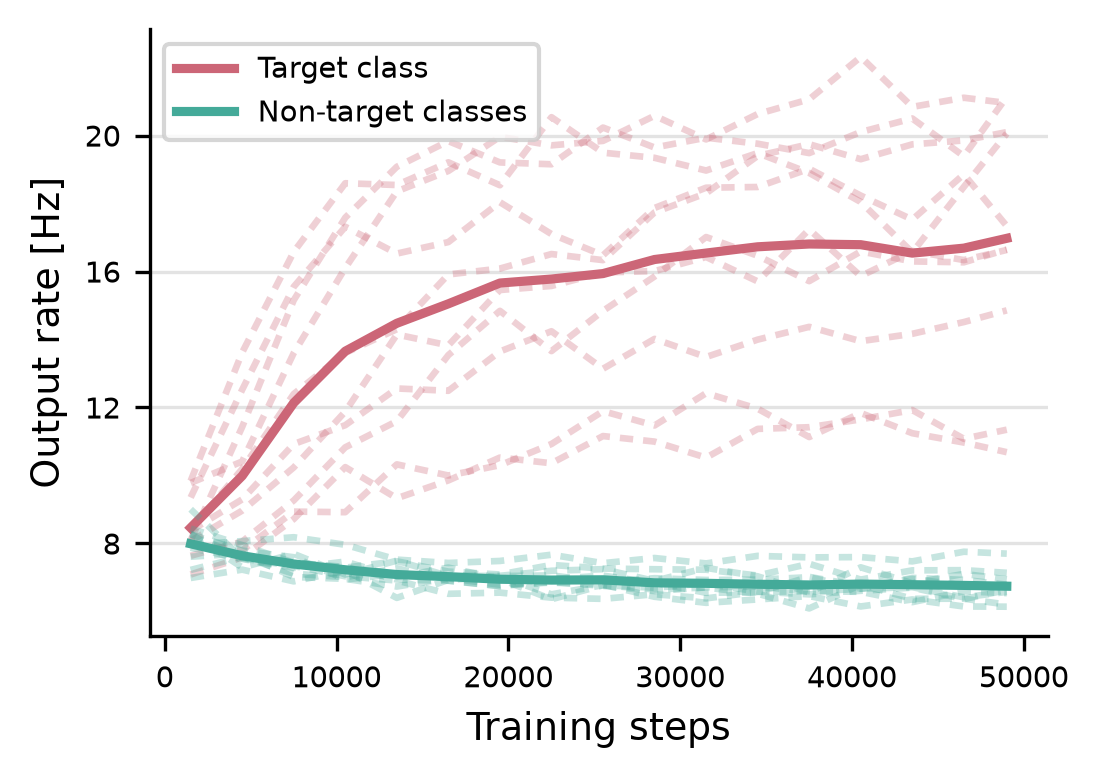

In [11]:
dyn_feedback_df = pd.read_csv('../data/dynapse/mnist1d_feedback_current.csv')
dyn_feedback_target_agg = pu.aggregate_binned(dyn_feedback_df, 'target_rate', group_cols=['class'], bin_size=150)
dyn_feedback_nontarget_agg = pu.aggregate_binned(dyn_feedback_df, 'nontarget_rate', group_cols=['class'], bin_size=150)
fig = pu.plot_feedback_current(dyn_feedback_target_agg, dyn_feedback_nontarget_agg)
fig.savefig('../figures/fig3f.pdf', bbox_inches='tight')
fig.savefig('../figures/fig3f.png', bbox_inches='tight')

### Figure 4 b

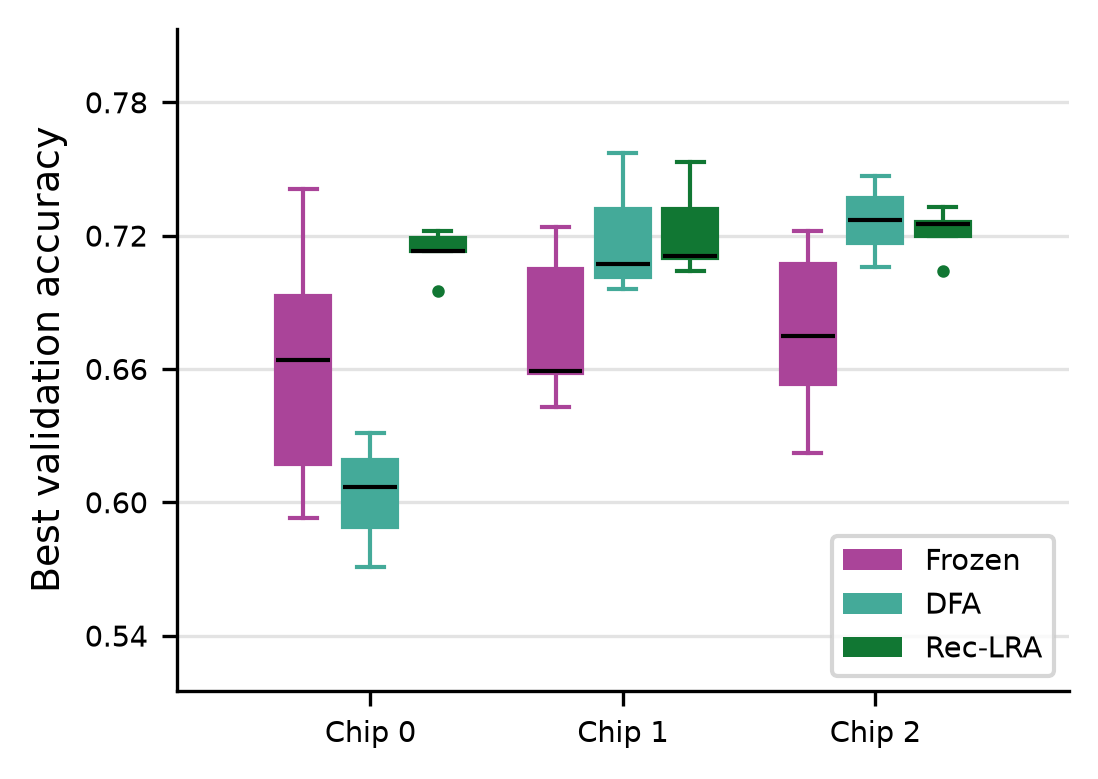

In [12]:
dyn_yinyang_df = pd.read_csv('../data/dynapse/yinyang_accuracy.csv')
fig = pu.plot_grouped_box_by_chip(dyn_yinyang_df, legend_loc='lower right')
fig.savefig('../figures/fig4b.pdf', bbox_inches='tight')
fig.savefig('../figures/fig4b.png', bbox_inches='tight')

### Figure 4 c

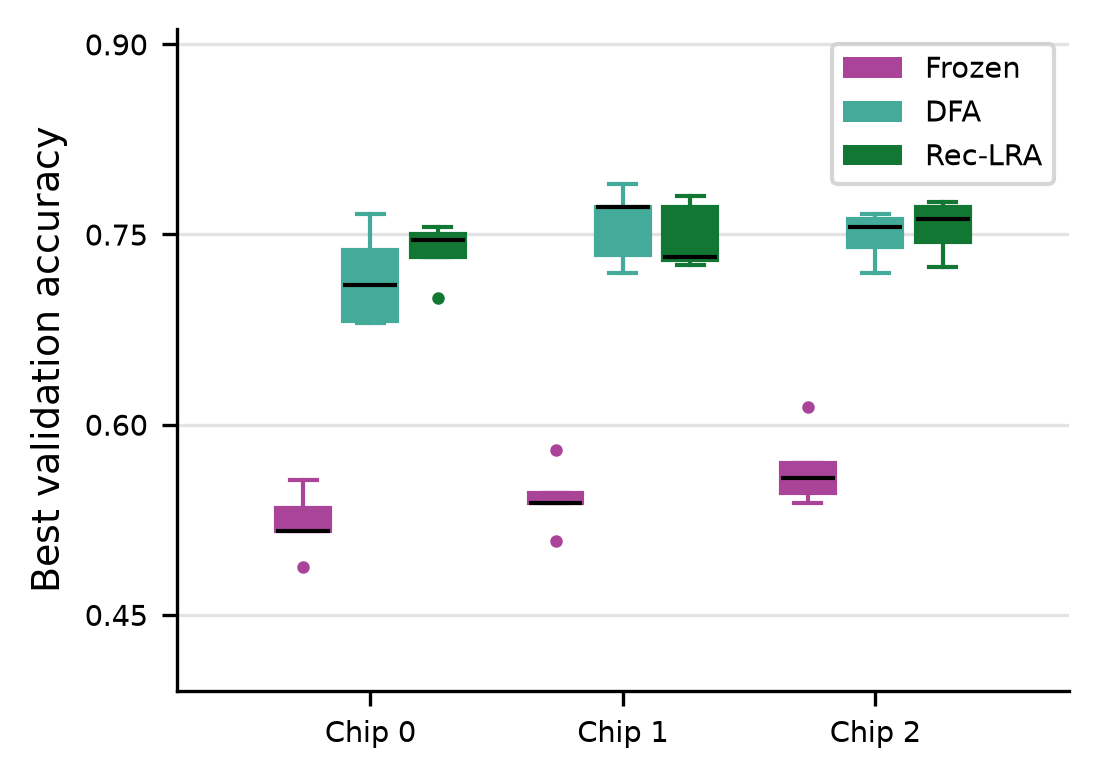

In [13]:
dyn_mnist1d_df = pd.read_csv('../data/dynapse/mnist1d_accuracy.csv')
fig = pu.plot_grouped_box_by_chip(dyn_mnist1d_df)
fig.savefig('../figures/fig4c.pdf', bbox_inches='tight')
fig.savefig('../figures/fig4c.png', bbox_inches='tight')

### Supplementary plots

#### Feature maps at init & test for different chips

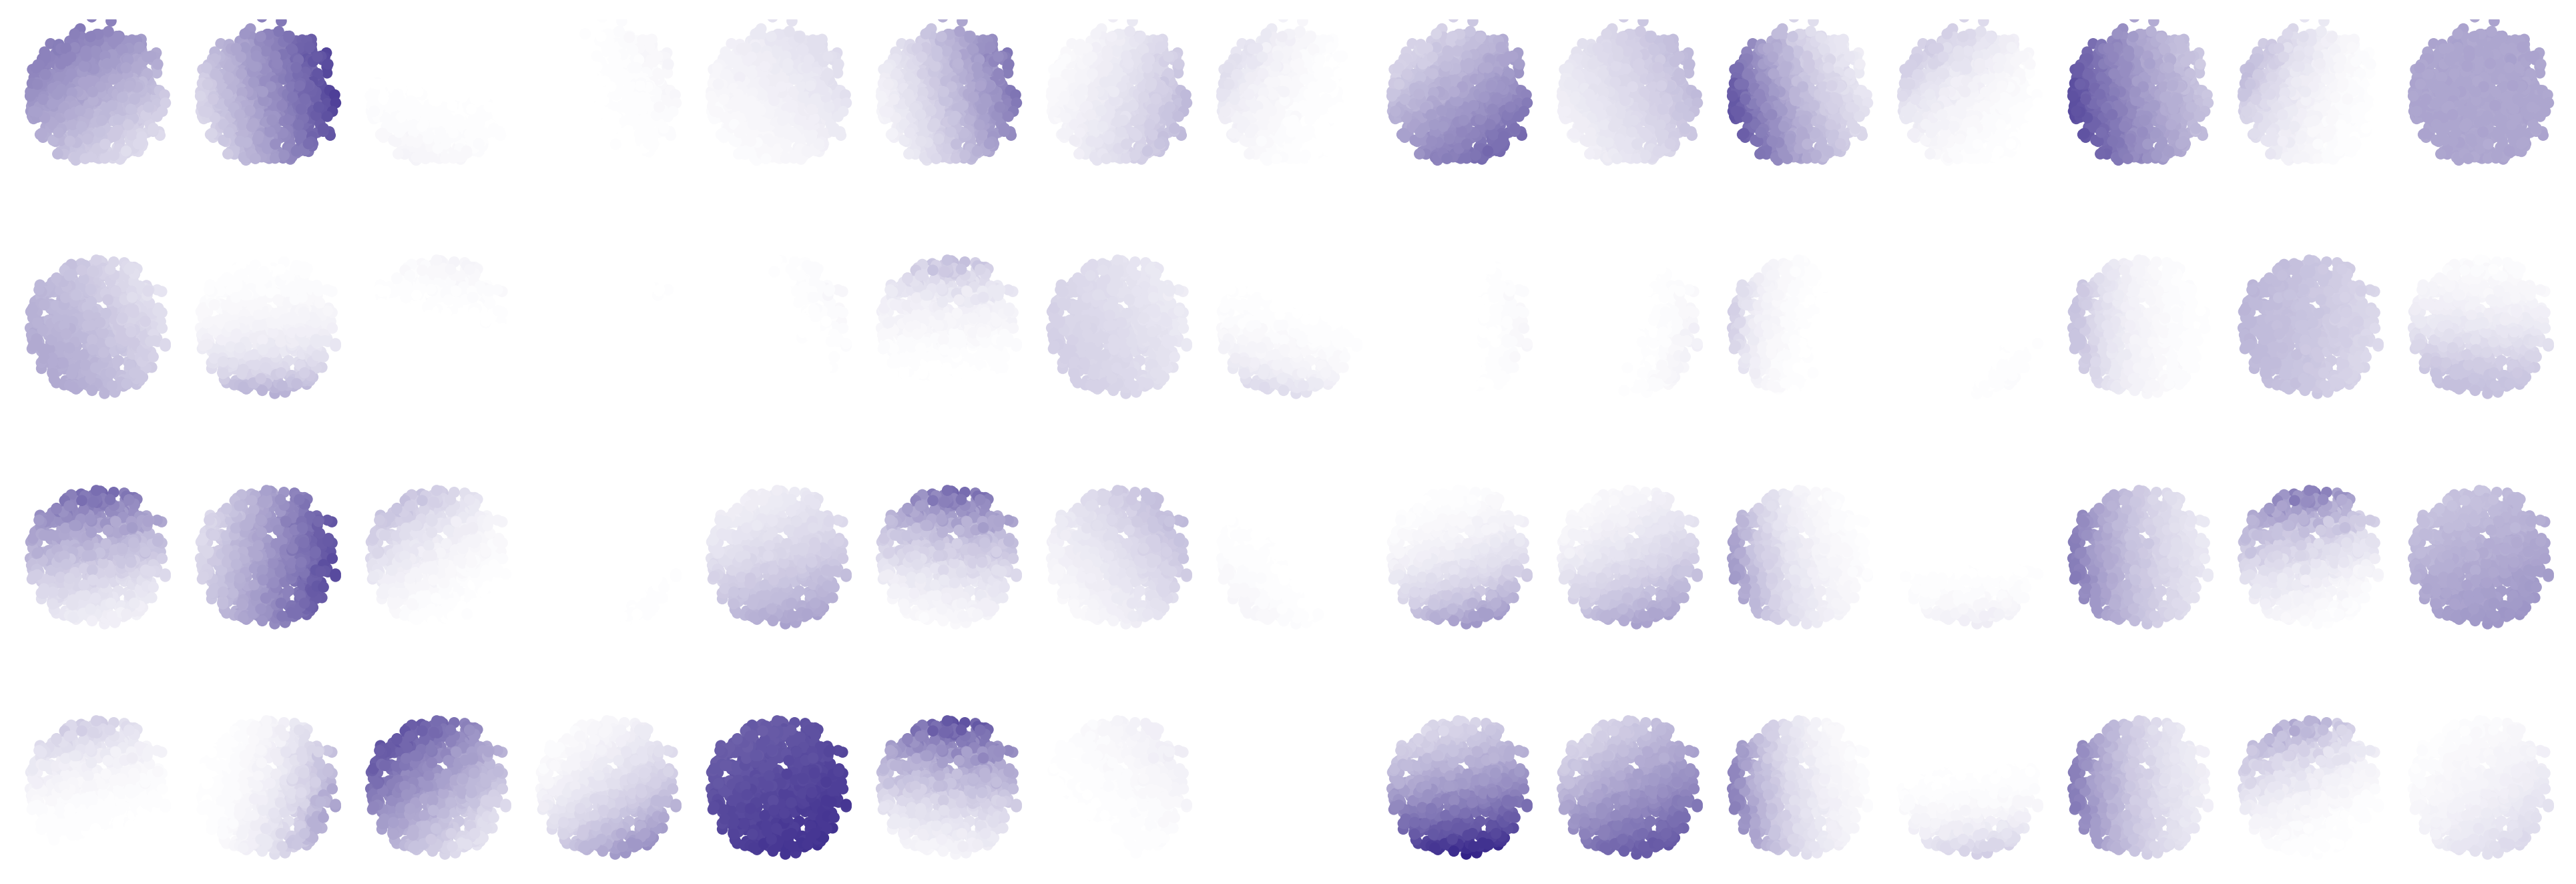

In [14]:
dyn_hidden_df = pd.read_csv('../data/dynapse/yinyang_hidden_activity.csv')
fig = pu.plot_hidden_feature_maps_across_chips(dyn_hidden_df, chips=[0, 1, 2], init_chip=2, init_step=0, final_step=75000)
fig.savefig('../figures/fig4d_supplementary.pdf', bbox_inches='tight')
fig.savefig('../figures/fig4d_supplementary.png', bbox_inches='tight')

#### Full hidden layer feature maps (chip 2, all neurons)

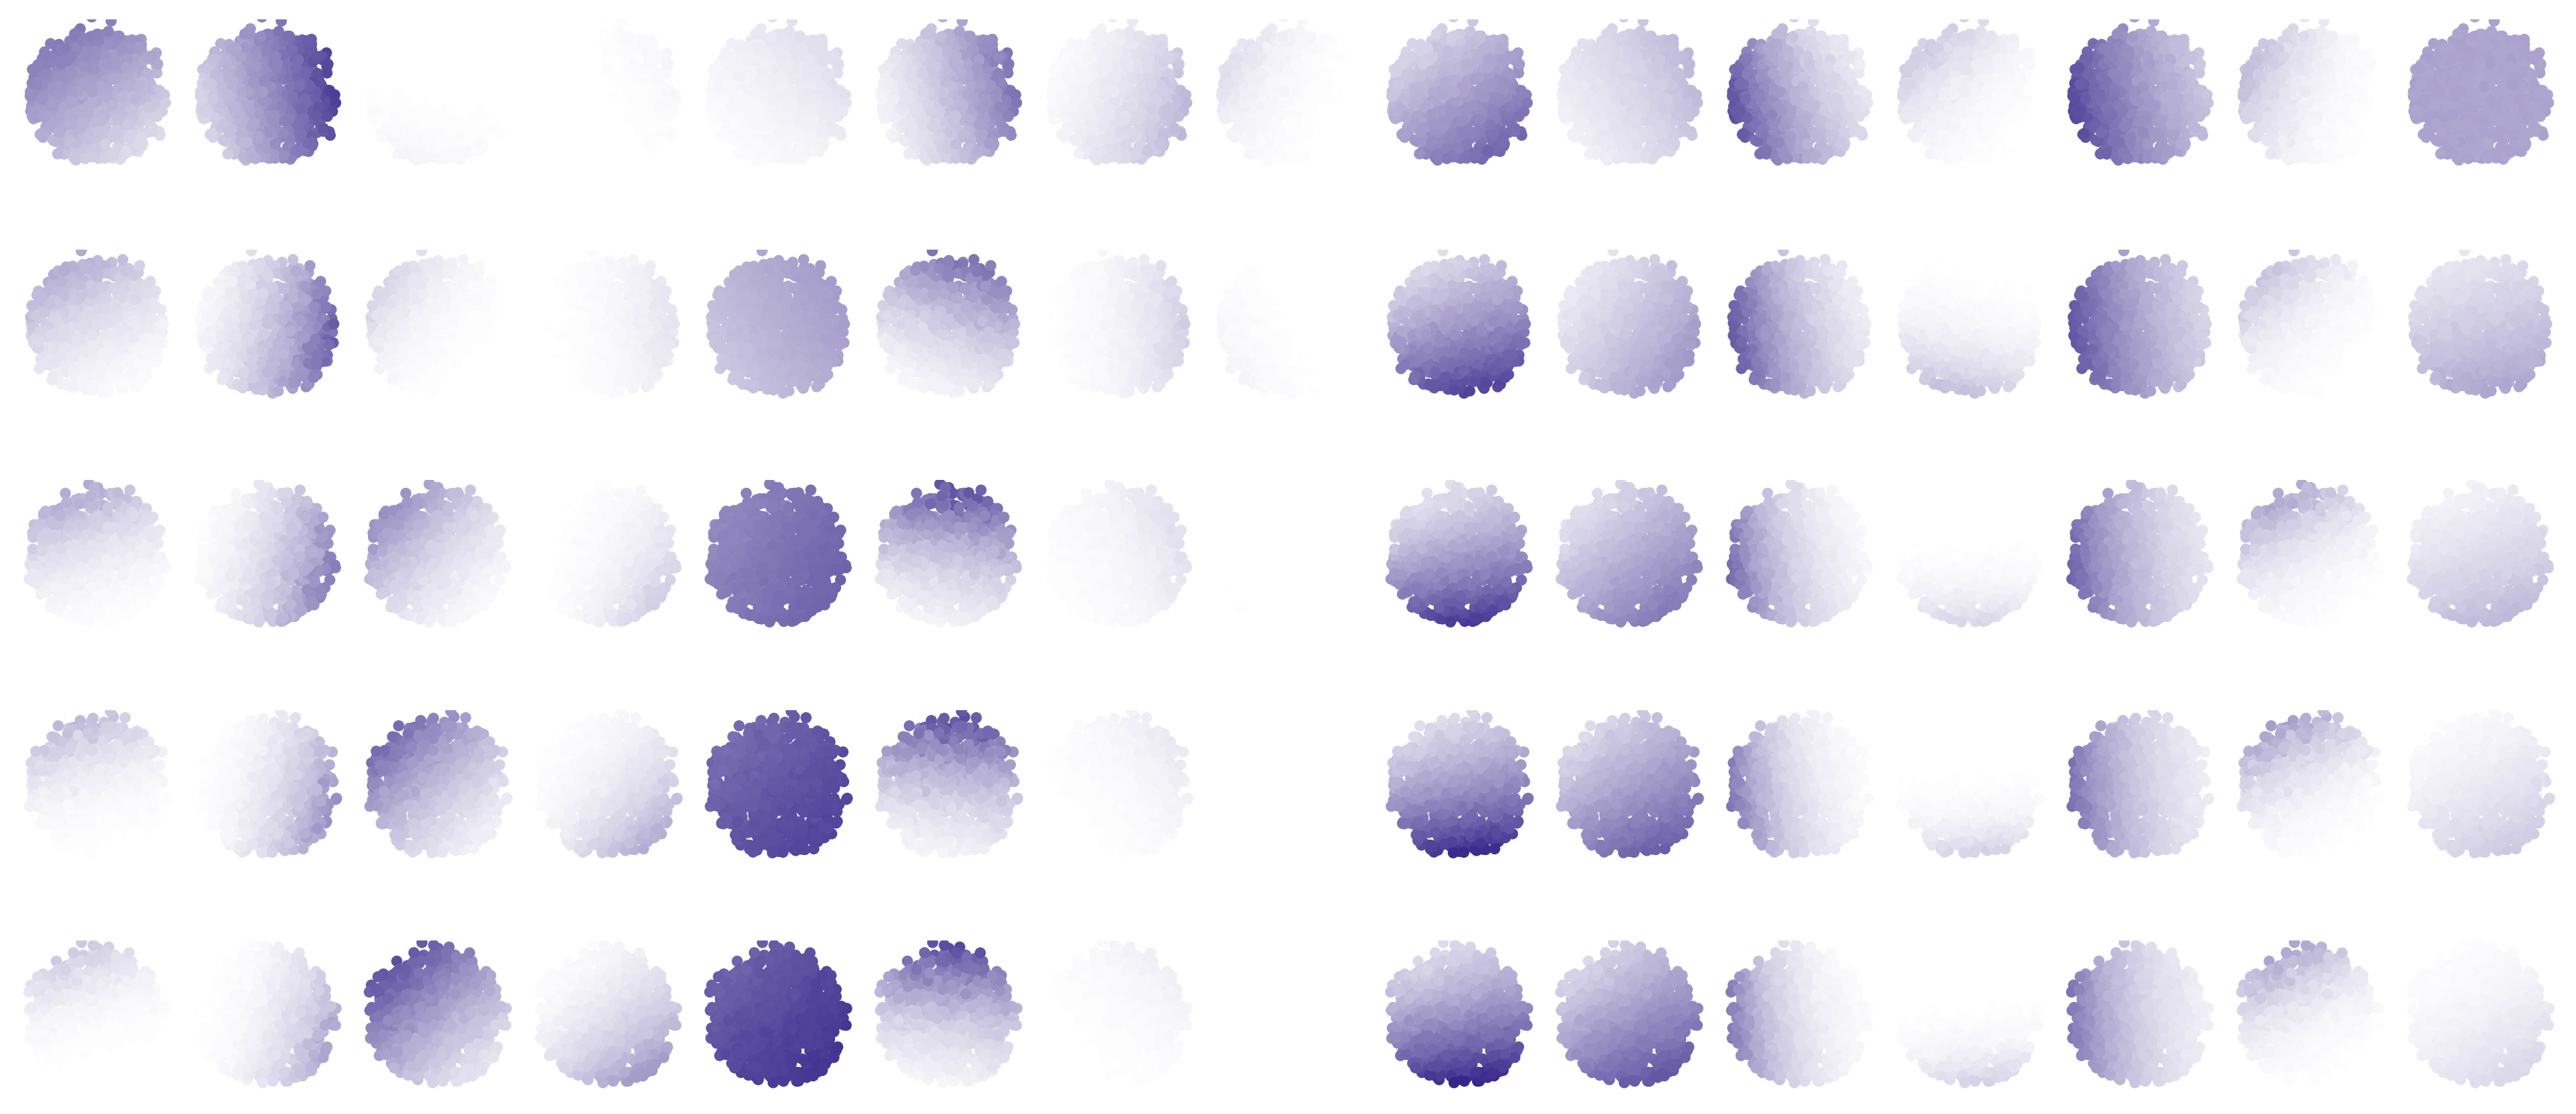

In [15]:
dyn_hidden_df = pd.read_csv('../data/dynapse/yinyang_hidden_activity.csv')
fig2d_steps = [0, 5000, 25000, 45000, 65000]
fig = pu.plot_hidden_feature_maps(dyn_hidden_df[(dyn_hidden_df['chip'] == 2) & (dyn_hidden_df['step'].isin(fig2d_steps))])
fig.savefig('../figures/fig2d_supplementary.pdf', bbox_inches='tight')
fig.savefig('../figures/fig2d_supplementary.png', bbox_inches='tight')

#### Accuracy over training with smaller populations (mnist1d, n_pop=2)

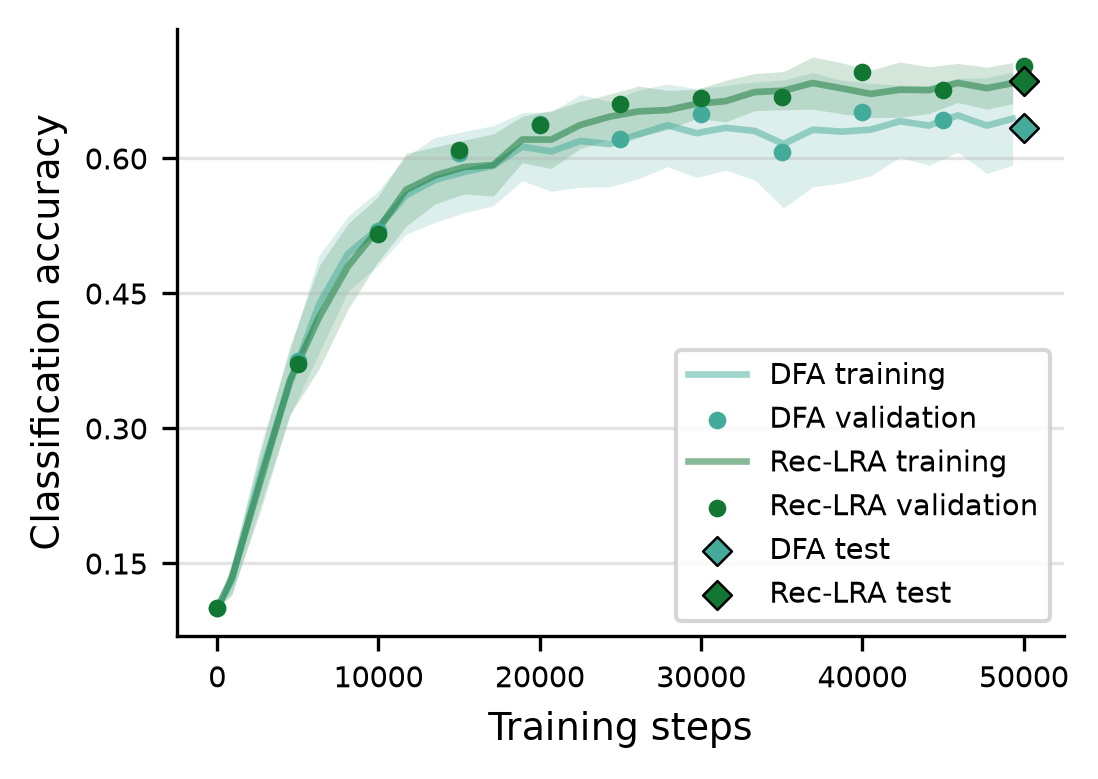

In [16]:
# n_pop=2 (DFA vs. Rec-LRA, re-tuned learning rates), same style as 3b. n_pop=8 is the main 3b/3c data.
dyn_npop2_df = pd.read_csv('../data/dynapse/mnist1d_npop2_accuracy.csv')
fig = pu.plot_population_accuracy_over_steps(dyn_npop2_df, n_pop=2, chance_level=0.1)  # 10 classes
fig.savefig('../figures/npop2_training_curves.pdf', bbox_inches='tight')
fig.savefig('../figures/npop2_training_curves.png', bbox_inches='tight')